## Context

This notebook accompanies User Guide section 20 (Orchestrator). It builds a `Scenario` with a forbidden-tool clause and a tool-call budget, runs a four-step plan through the `GovernedOrchestrator`, demonstrates the forbidden-tool abort path, exercises the optional `OrchestratorPolicy` co-attestor, and visualizes the lifecycle as a step timeline. The notebook reuses the `ds_practices_store` fixture so no rebuild is needed.

In [1]:
# Phase 4c preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _shared as ug
ug.bootstrap_runtime()
from user_guide_tutorials.notebooks import _helpers_phase4c as h4c
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


Device: cuda, CUDA available: True


### Concept: scenarios, lifecycles, and a second attestor

A `Scenario` is the behavioral contract the orchestrator enforces. The four fields that drive enforcement are `required_tools`, `forbidden_tools`, `expected_tool_sequence`, and `max_tool_calls`. Required tools that are missing produce scenario violations; forbidden tools are recorded as violations *and* filtered out before execution; sequence violations are checked at evaluation time; budget overruns transition the run to ABORTED.

The lifecycle is a finite-state machine: CREATED -> PREPARING -> EXECUTING -> EVALUATING -> COMPLETED. Three exits to ABORTED exist: a budget overrun, a co-attestor refusal in PREPARING, or a tool-error abort during EXECUTING. The tool-error path matters because a tool can succeed at all three gates but still return an error in `raw["error"]` (for example, `load_dataset` with an unknown built-in); without the explicit guard, the run would silently complete with zero claims and the default PASS-on-empty path would sign off on a failure.

The orchestrator accepts an optional `OrchestratorPolicy` co-attestor — a pure-Python rule pack that runs against the `(plan, scenario)` tuple before EXECUTING. The default rule pack catches structural failure modes (unknown tools, circular dependencies, duplicate steps) that the geometric gates do not see. When the co-attestor refuses, the run transitions PREPARING -> ABORTED with the rule ids in the trace.

In [ ]:
from knowlytix.harness.governance.session import SessionState
from knowlytix.harness.governance.governed_gateway import GovernedToolGateway
from knowlytix.harness.governance.tools import TOOL_DEFINITIONS
from knowlytix.harness.governance.memory import AgentMemory
from knowlytix.harness.governance.verifier import ClaimVerifier
from knowlytix.harness.governance.orchestrator import (
    GovernedOrchestrator, Scenario,
)
from knowlytix.harness.governance.orchestrator_policy import (
    OrchestratorPolicy, default_orchestrator_rules,
)

# Load the prebuilt fixture and wire the gateway.
store = ug.load_ds_practices_store()
session = SessionState()
gateway = GovernedToolGateway(
    session=session,
    store=store,
    theta_plausibility=1.5,
    tool_schemas=TOOL_DEFINITIONS,
    device=str(DEVICE),
)

# AgentMemory binds to a fresh on-disk path so the run's
# findings do not leak into the shared fixture. /tmp is
# used so the canonical fixtures dir stays clean.
import shutil
_NB20_MEM = '/tmp/nb20_memory_store'
shutil.rmtree(_NB20_MEM, ignore_errors=True)
memory = AgentMemory(
    store_path=_NB20_MEM,
    device=str(DEVICE),
)
verifier = ClaimVerifier(store, device=str(DEVICE))
print('Setup OK. theta =', gateway.theta_plausibility)


### Build the scenario and a clean four-step plan

The contract requires `load_dataset` and `train_model`, forbids the unregistered tool name `delete_record`, and caps the budget at 20 tool calls. The plan exercises the canonical data-loading -> preprocess -> train -> diagnose sequence.

In [3]:
scenario = Scenario(
    name='nb20_iris',
    required_tools=['load_dataset', 'train_model'],
    forbidden_tools=['delete_record'],
    max_tool_calls=20,
)

clean_plan = [
    'load_dataset', 'preprocess_data',
    'train_model', 'diagnose_robustness',
]

orchestrator = GovernedOrchestrator(
    gateway=gateway, memory=memory, verifier=verifier,
    session=session, store=store, device=str(DEVICE),
    dataset_name='iris',
)
clean_result = orchestrator.run(clean_plan, scenario)
print(orchestrator.format_result(clean_result))


  [BackgroundTrain] Starting: 10 entities, 6 relations, 9 triples


  [BackgroundTrain] Done: Trained: 10 entities, 6 relations, 50 steps in 12.3s
  Store saved to /tmp/nb20_memory_store
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 2 entities, 3 relations, 3 triples


  [BackgroundTrain] Done: Trained: 2 entities, 3 relations, 50 steps in 8.0s
  Store saved to /tmp/nb20_memory_store
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 3 entities, 8 relations, 9 triples


  [BackgroundTrain] Done: Trained: 3 entities, 8 relations, 50 steps in 10.9s
  Store saved to /tmp/nb20_memory_store
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 4 entities, 7 relations, 7 triples


  [BackgroundTrain] Done: Trained: 4 entities, 7 relations, 50 steps in 11.2s
  Store saved to /tmp/nb20_memory_store
  [BackgroundTrain] Store saved
=== GovernedOrchestrator Result ===
  Final state: failed
  Steps executed: 4
  Total time: 42570 ms

--- Lifecycle Transitions ---
  created      -> preparing     at 19:20:07
  preparing    -> executing     at 19:20:07
  executing    -> evaluating    at 19:20:49
  evaluating   -> failed        at 19:20:49

--- Verification Verdict ---
  Status: FAIL
  Passed: 16/34 (47.1%)

--- Signal Availability ---
  Steps with unavailable plausibility signal: 4/4 (100.0%)

--- Steps ---
  [ 0] load_dataset              OK      | tier=1 facts=13 | sigma(sim=N/A, ver=1.000, depth=0.250, nov=1.000, margin=N/A, signal_unavailable=True)
  [ 1] preprocess_data           OK      | tier=2 facts= 6 | sigma(sim=N/A, ver=1.000, depth=0.500, nov=1.000, margin=N/A, signal_unavailable=True)
  [ 2] train_model               OK      | tier=1 facts=16 | sigma(sim=N/A

### Inject a forbidden tool mid-plan and observe the abort

We now insert `delete_record` between the train and diagnose steps. The orchestrator records a scenario violation in PREPARING, filters the forbidden step out before EXECUTING, and the corresponding `step_record` for that index is never produced — only the executable steps appear in `steps_executed`. The point: the forbidden tool never reaches the gateway, so it cannot fire even if its schema would otherwise pass.

In [4]:
tampered_plan = [
    'load_dataset', 'preprocess_data',
    'train_model', 'delete_record',  # injected
    'diagnose_robustness',
]
tampered_result = orchestrator.run(tampered_plan, scenario)
print('--- Scenario violations ---')
for v in tampered_result.scenario_violations:
    print(' ', v)
print()
executed_tools = [s['tool'] for s in tampered_result.steps_executed]
print('Executed tools (forbidden filtered):', executed_tools)
assert 'delete_record' not in executed_tools, (
    'forbidden tool reached EXECUTING')


  [BackgroundTrain] Starting: 2 entities, 0 relations, 7 triples


  [BackgroundTrain] Done: Trained: 2 entities, 0 relations, 50 steps in 7.4s
  Store saved to /tmp/nb20_memory_store
  [BackgroundTrain] Store saved
--- Scenario violations ---
  Forbidden tool 'delete_record' present in plan

Executed tools (forbidden filtered): ['load_dataset', 'preprocess_data', 'train_model', 'diagnose_robustness']


### Demonstrate the `OrchestratorPolicy` co-attestor

The default rule pack ships eight rules. Rule `O4_no_circular_dependencies` requires that `load_dataset` come before `train_model` whenever both appear. We construct a deliberately-wrong plan that trains before loading, attach the co-attestor, and observe the PREPARING -> ABORTED transition. The trace carries the failing rule id.

In [5]:
policy = OrchestratorPolicy(default_orchestrator_rules())
policy_orch = GovernedOrchestrator(
    gateway=gateway, memory=memory, verifier=verifier,
    session=session, store=store, device=str(DEVICE),
    dataset_name='iris', plan_policy=policy,
)

# Train before load_dataset -> O4 fires.
circular_plan = ['train_model', 'load_dataset',
                 'diagnose_robustness']
policy_result = policy_orch.run(circular_plan, scenario)
print('Final state:', policy_result.state.value)
print('Violations:')
for v in policy_result.scenario_violations:
    print(' ', v)
# Single main attestor (gateway gates 1-3 + ClaimVerifier);
# the co-attestor would add a structural rule pack with
# uncorrelated blind spots (unknown tools, circular deps,
# duplicate steps) — both must agree to COMPLETE.


Final state: aborted
Violations:
  plan_policy: O4_no_circular_dependencies: If train_model and load_dataset are both present, load_dataset must come first.


### Visualization: lifecycle timeline of the tampered run

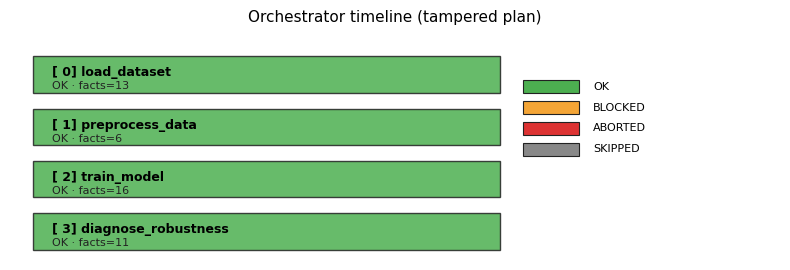

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 0.7 * max(
    1, len(tampered_result.steps_executed))))
h4c.plot_orchestrator_timeline(
    ax, tampered_result.steps_executed,
    title='Orchestrator timeline (tampered plan)',
)
plt.tight_layout()
plt.show()


### Exercises

1. Add `'expected_tool_sequence': ['load_dataset', 'train_model']` to the scenario and run a plan that violates the order. Confirm the EVALUATING phase records the sequence violation.
2. Drop `max_tool_calls` to `2` and rerun the clean plan. Verify the orchestrator transitions to ABORTED with a budget-exhausted violation, and that `format_result` shows the partial trace.
3. Add a custom `OrchestratorRule` that forbids `explain_*` tools from appearing without `diagnose_robustness` first. Confirm the new rule blocks a plan that violates it.

### What you should now be able to do

- Compose a `Scenario` with `required_tools`, `forbidden_tools`, and `max_tool_calls` clauses.
- Read an `OrchestratorResult`: lifecycle state, violations, signal vectors, claim verdict.
- Recognize the four exit paths from EXECUTING: COMPLETED, FAILED, budget-ABORTED, tool-error-ABORTED.
- Wire an `OrchestratorPolicy` co-attestor and reason about why two attestors with uncorrelated blind spots outperform either alone.
- Render a step-timeline visualization for an audit review.

In [7]:
# Final assertion: the forbidden-tool injection aborts
# before tool execution. The forbidden step never appears
# in steps_executed, and the scenario violation is
# recorded.  blocked=True specifically refers to gateway-
# blocked steps; in this filter-path implementation the
# step is removed before EXECUTING, so we assert on the
# stronger invariant: the forbidden tool was never run.
executed_tools = [s['tool']
                  for s in tampered_result.steps_executed]
assert 'delete_record' not in executed_tools
assert any('delete_record' in v
           for v in tampered_result.scenario_violations)
# TODO(p7-execute): if Phase 7 builds an end-to-end
# blocked_step_record (where blocked=True for filtered
# forbidden tools), tighten this to
# `assert forbidden_step.blocked is True`.
print('PASS: forbidden tool was filtered and recorded as a violation.')


PASS: forbidden tool was filtered and recorded as a violation.
